In [5]:
import magnumnp as mp
import torch
import numpy as np
import matplotlib.pyplot as plt 
from tqdm import tqdm 
from scripts.read_field import field_image

ModuleNotFoundError: No module named 'scripts'

In [35]:
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
torch.set_default_device(device)
torch.set_default_dtype(torch.float32)



$$
\mathbf G \times \mathbf v + \mathbf \eta_\text{Sk} \cdot \mathbf v = \mathbf F_\text{Sk},\quad \sigma_\text{v} \mathbf v = \mathbf F_\text{v}
$$
$$
\sigma \sim \cfrac{G^2 + \eta_\text{Sk}^2}{\eta_\text{Sk}}
$$
$$
\eta_{\text{Sk}} \sim \alpha |\mathbf D| \sim \alpha \cfrac{M_s d_\text{F}}{|\gamma_e|} \int |\partial_r m|^2 d^2 r \sim \alpha \cdot 2 \cdot 10^{-14}\,\text{Н$\cdot$с/м}
$$
$$
|\mathbf G| = \cfrac{4\pi |Q| M_s d_F}{|\gamma_e|} \sim 1.8 \cdot 10^{-14}\,\text{Н$\cdot$с/м}
$$
$$
\sigma \sim \cfrac{\alpha^2 + 1}{\alpha} \cdot 2 \cdot 10^{-14}\,\text{Н$\cdot$с/м}
$$

In [39]:
class PearlVortex:
    """Rigid vortex field and overdamped motion for a single magnetic plane.

    Parameters
    ----------
    state : mp.State
        Simulation state
    pos : tuple of float
        Initial vortex position (x, y) in metres
    lambdaP : float
        Pearl length in metres, defined as lambdaL**2 / ds for a film
        of positive thickness, where lambdaL is the London penetration depth
    phi0 : float
        Positive magnetic flux quantum in webers
    sigma : float
        Vortex drag coefficient in N s/m
    z : float
        Positive sampling height in metres above the superconducting surface
        z = d_F / 2 for the middle of the film
    ds : float
        Superconducting film thickness in metres in Eq. (D2).
        ds = 0 for thin film approximation (D3)
    polarity : {-1, +1}
        Sign of the vortex flux. The value -1 follows Eq. (D1).

    Call build_profile before sampling B or H or computing the vortex force.
    A mesh periodic in both in-plane directions uses the periodic image
    sum of the D1 field. An open mesh uses the isolated radial profile.
    """

    def __init__(
        self, state: mp.State,
        pos=(0.0, 0.0),
        lambdaP=200e-9,
        phi0=2.067833848e-15,
        sigma=1.0,
        z=2.5e-9,
        ds=10e-9,
        polarity=-1,
    ):
        if lambdaP <= 0 or ds < 0 or z <= 0 or sigma <= 0:
            raise ValueError("Require lambdaP, z and sigma > 0, and ds >= 0.")
        if polarity not in (-1, 1):
            raise ValueError("Vortex polarity must be -1 or +1.")
        self.pos = state.m.new_tensor(pos)
        self.lambdaP = float(lambdaP)
        self.ds = float(ds)
        self.z = float(z)
        self.flux = polarity * float(phi0)
        self.sigma = float(sigma)
        self._mesh = state.mesh
        x, y, _ = self._mesh.SpatialCoordinate()
        self._x = x[:, :1, :1]
        self._y = y[:1, :, :1]
        pbc_x, pbc_y = (bool(p) for p in self._mesh.pbc[:2])
        if pbc_x != pbc_y or (pbc_x and not self._mesh.is_equidistant):
            raise ValueError("Periodic vortex sampling needs a uniform mesh periodic in x and y.")
        self._periodic = pbc_x
        self._h_cache = None

    def screening(self, q):
        if self.ds == 0:
            return 1 + 2 * q * self.lambdaP  # Eq. D3

        # Eq. D2:
        # F = lambdaL^2 tau [tau + q coth(tau ds / 2)].
        lambdaL = np.sqrt(self.lambdaP * self.ds)
        tau = np.hypot(q, 1 / lambdaL)
        return (lambdaL * tau) ** 2 + self.lambdaP * q * (
            (tau * self.ds) / np.tanh(tau * self.ds / 2)
        )

    def build_profile(self, state, r_max, Nr=8193):
        if self._periodic:
            self._build_periodic_profile(state)
            self._h_cache = None
            return

        if r_max <= 0 or Nr < 2:
            raise ValueError("Require r_max > 0 and at least two radial samples.")

        # At the upper limit the height factor is exp(-32).
        q_max = 32 / self.z
        n_panels = int(np.ceil(q_max * max(r_max / (2 * np.pi), self.lambdaP / 2)))
        edges = np.linspace(0, q_max, n_panels + 1)
        nodes, weights = np.polynomial.legendre.leggauss(8)
        half_width = q_max / (2 * n_panels)
        q = (edges[:-1, None] + half_width * (1 + nodes)).ravel()
        weight = (half_width * weights[None, :] * (
            q * np.exp(-q * self.z) / self.screening(q)
        ).reshape(n_panels, -1)).ravel()
        weight *= self.flux / (2 * np.pi)

        rho = np.linspace(0, r_max, Nr)
        profile = np.empty((Nr, 2))
        for start in range(0, Nr, 64):
            radii = rho[start:start + 64]
            qr = radii[:, None] * q
            profile[start:start + len(radii), 0] = special.j1(qr) @ weight
            profile[start:start + len(radii), 1] = special.j0(qr) @ weight

        # Tabulate Br/r so Bxy = (Br/r) * displacement, including at r=0.
        profile[1:, 0] /= rho[1:]
        profile[0, 0] = weight @ (q / 2)
        self._table = state.m.new_tensor(profile)
        self.dr = r_max / (Nr - 1)
        self._h_cache = None

    def _build_periodic_profile(self, state):
        # Sample the Fourier series on a finer grid for cheap subcell shifts.
        # Keep only modes below the simulation mesh Nyquist frequencies.
        nx, ny = self._mesh.n[:2]
        dx, dy = self._mesh.dx[:2]
        oversampling = 4
        shape = (oversampling * nx, oversampling * ny)
        self._periodic_step = (dx / oversampling, dy / oversampling)
        kx = 2 * np.pi * np.fft.fftfreq(shape[0], self._periodic_step[0])[:, None]
        ky = 2 * np.pi * np.fft.rfftfreq(shape[1], self._periodic_step[1])[None, :]
        q = np.hypot(kx, ky)
        # NumPy divides the inverse transform by the fine-grid point count.
        amplitude = self.flux / (dx * dy) * oversampling**2
        bz = amplitude * np.exp(-q * self.z) / self.screening(q)
        bz *= (abs(kx) < np.pi / dx) & (abs(ky) < np.pi / dy)
        q[0, 0] = 1  # In-plane field has zero mean.
        profile = np.empty((*shape, 3))
        for component, spectrum in enumerate((-1j * kx * bz / q, -1j * ky * bz / q, bz)):
            profile[..., component] = np.fft.irfft2(spectrum, s=shape, axes=(0, 1))
        self._periodic_table = state.m.new_tensor(profile)
        self._periodic_indices = (
            torch.arange(nx, device=state.m.device)[:, None, None] * oversampling,
            torch.arange(ny, device=state.m.device)[None, :, None] * oversampling,
        )

    def _sample_periodic(self, x, y, pos, on_mesh):
        step_x, step_y = self._periodic_step
        table = self._periodic_table
        if on_mesh:
            # A rigid shift shares one interpolation fraction across all cells.
            ix, iy = self._periodic_indices
            u = (self._x[0, 0, 0] - pos[0]) / step_x
            v = (self._y[0, 0, 0] - pos[1]) / step_y
        else:
            ix, iy = 0, 0
            u, v = (x - pos[0]) / step_x, (y - pos[1]) / step_y
        u0, v0 = u.floor(), v.floor()
        fx, fy = (u - u0).unsqueeze(-1), (v - v0).unsqueeze(-1)
        i0, j0 = (ix + u0.long()) % table.shape[0], (iy + v0.long()) % table.shape[1]
        i1, j1 = (i0 + 1) % table.shape[0], (j0 + 1) % table.shape[1]
        lower = torch.lerp(table[i0, j0], table[i1, j0], fx)
        upper = torch.lerp(table[i0, j1], table[i1, j1], fx)
        return torch.lerp(lower, upper, fy)

    def B(self, state, pos=None):
        """Sample Cartesian B in tesla on the mesh or at (..., 2) tensor points.
        Points are in metres and should share the profile device and dtype.
        The result has shape (..., 3)."""
        pos = self.pos if pos is None else pos
        on_mesh = not isinstance(state, torch.Tensor)
        if not on_mesh:
            x, y = state.unbind(dim=-1)
        else:
            if state.mesh is not self._mesh:
                raise ValueError("State must use the mesh used to construct the vortex.")
            x, y = self._x, self._y
        if self._periodic:
            return self._sample_periodic(x, y, pos, on_mesh)
        dx, dy = x - pos[0], y - pos[1]

        # Use r^2 interpolation in the first bin to keep Bz differentiable at the axis.
        u2 = (dx / self.dr).square() + (dy / self.dr).square()
        radius = u2.clamp(min=1).sqrt()
        u = radius.clamp(max=len(self._table) - 1)
        index = u.long().clamp(max=len(self._table) - 2)
        fraction = torch.where(u2 < 1, u2, u - index)
        values = torch.lerp(self._table[index], self._table[index + 1], fraction.unsqueeze(-1))
        br_over_r, bz = values.unbind(dim=-1)
        # Hold the endpoint field magnitude outside the tabulated radius.
        br_over_r = br_over_r * ((len(self._table) - 1) / radius).clamp(max=1)
        return torch.stack((br_over_r * dx, br_over_r * dy, bz), dim=-1)

    def H(self, state: mp.State):
        """Return A/m, reusing the field across LLG stages at the same position."""
        if self.pos.requires_grad or torch.is_inference(self.pos):
            return self.B(state) / mp.constants.mu_0
        if state.mesh is not self._mesh:
            raise ValueError("State must use the mesh used to construct the vortex.")
        cached = self._h_cache
        if cached is None or cached[0] is not self.pos or cached[1] != self.pos._version:
            cached = (self.pos, self.pos._version, self.B(state) / mp.constants.mu_0)
            self._h_cache = cached
        return cached[2]

    def interaction_energy(self, state: mp.State, pos):
        """Zeeman energy relative to the uniformly +z magnetized state."""
        B = self.B(state, pos)
        mx, my, mz = state.m.unbind(dim=-1)
        bx, by, bz = B.unbind(dim=-1)
        relative_dot = mx * bx + my * by + (mz - 1) * bz
        density = -state.material["Ms"] * relative_dot.unsqueeze(-1)
        return (density * state.mesh.cell_volumes).sum()

    def velocity(self, state: mp.State):
        """Overdamped motion with drag sigma in N s/m."""
        with torch.enable_grad():
            pos = self.pos.detach().requires_grad_(True)
            energy = self.interaction_energy(state, pos)
            force = -torch.autograd.grad(energy, pos)[0]
        return force / self.sigma

    def advance(self, state: mp.State, dt):
        v = self.velocity(state)
        self.pos = (self.pos + v * dt).detach()
        return v

In [42]:
mp.Timer.enable()

L = 7e-7
dx = (2.5e-9, 2.5e-9, 2.5e-9)
n = (int(2 * L / dx[0]) + 1, int(2 * L /  dx[1]) + 1, 1)
origin = (-L, -L, 0)
mesh = mp.Mesh(n, dx, origin, pbc=(1,1,0))

state = mp.State(mesh)
Ms0 = 1e5
K_eff = 1000.0  # Paper's K, in J/m^3. Demagnetization is folded into K.
A0 = 1e-11
lw = np.sqrt(A0 / K_eff)

gamma = 0.15
phi0 = 2.067833848e-15

# Set lambda using Eq. (45). The D1/D2 profile retains the chosen ds and z.
lambdaP = float(
    Ms0 * phi0 / (8 * np.pi * gamma * np.sqrt(A0 * K_eff))
)
state.material = {
    "Ms": Ms0,
    "A": A0,
    "Ku": K_eff,
    "Ku_axis": (0, 0, 1.0),
    "Di": 2 * 0.3 * 1e-4,
    "alpha": 0.1,
}
def e_dmi(state: mp.State):
    X, Y, _ = state.mesh.SpatialCoordinate()
    x_tip, y_tip = 2 * lw, 0
    D = 1e-4
    beta = 0
    epsilon = 0.45
    r2 = (X - x_tip) ** 2 + (Y - y_tip) ** 2
    return 2 * D * (epsilon + beta * lw ** 3 / (r2 + lw ** 2) ** 1.5)

state.material['Di'] = e_dmi(state)

def skyrmion(state: mp.State):
    X, Y, _ = state.mesh.SpatialCoordinate()
    R = 1 * lw
    w = 1 * lw
    r = torch.sqrt(X ** 2 + Y ** 2)
    theta = 2 * torch.arctan(np.sinh(R / w) / torch.sinh(r / w))
    phi = torch.atan2(Y, X)
    mx = torch.sin(theta) * torch.cos(phi)
    my = torch.sin(theta) * torch.sin(phi)
    mz = torch.cos(theta)
    return torch.stack([mx, my, mz], dim=-1)

state.m = skyrmion(state)

vortex = PearlVortex(
    state,
    pos=(0.5 * lw, 0.5 * lw),
    lambdaP=lambdaP,
    phi0=phi0,
    ds=10e-9,
    z=dx[2] / 2,
    polarity=-1,
    sigma=1e-15,
)

vortex.build_profile(
    state,
    r_max=np.hypot(n[0] * dx[0], n[1] * dx[1]),
    Nr=8193,
)
vortex_field = mp.ExternalField(
    vortex.H
)

exchange = mp.ExchangeField()
anisotropy = mp.UniaxialAnisotropyField()
dmi = mp.InterfaceDMIField()

llg = mp.LLGSolver([
    exchange,
    anisotropy,
    dmi,
    vortex_field,
])

states = [state.m.clone().detach().cpu().reshape((n[0], n[1], 3)).swapaxes(0,1)]
vortex_positions = [vortex.pos.cpu().numpy().copy()]

dt = 1e-11
for i in tqdm(range(1001)):
    vortex.advance(state, dt / 2)
    llg.step(state, dt)
    vortex.advance(state, dt / 2)
    if i % 10 == 1:
        states.append(state.m.clone().detach().cpu().reshape((n[0], n[1], 3)).swapaxes(0,1))
        vortex_positions.append(vortex.pos.cpu().numpy().copy())

2026-11-19 08:05:44  magnum.np:INFO [State] running on device: mps:0 (dtype = float32)
2026-11-19 08:05:44  magnum.np:INFO [Mesh] 561x561x1 (dx= 2.5e-09 x 2.5e-09 x 2.5e-09, pbc=[1,1,0])
2026-11-19 08:05:44  magnum.np:INFO [LLGSolver] using RKF45 solver (atol = 1e-05)
100%|██████████| 1001/1001 [13:20<00:00,  1.25it/s]


0
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
0


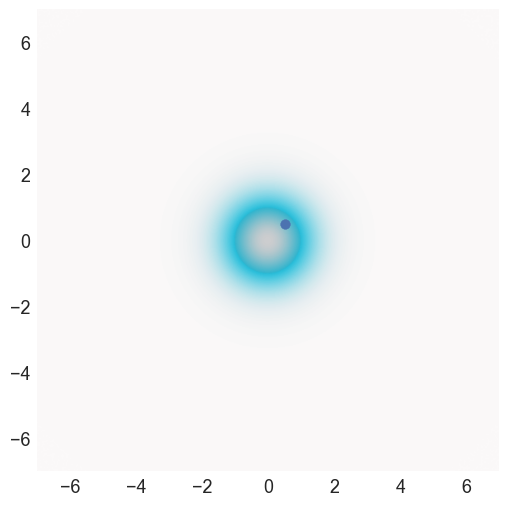

In [43]:
from matplotlib import animation
from matplotlib.patches import Circle
from cmap import Colormap, Color

name = '01_simple_noncoaxial'

_cmap = Colormap('colorcet:cet_cbtc2').to_mpl()
_cmap2 = Colormap('colorbrewer:YlGn_3').to_mpl()
cmap = Colormap([_cmap(0), _cmap(0), _cmap2(0.5), _cmap(0.5), _cmap2(1), _cmap(1)]).to_mpl()

fig, ax = plt.subplots()
def update(i):
    print(i)
    ax.clear()
    m = states[i].numpy()
    # B = vortex_field([mesh[0].cpu(), mesh[1].cpu()], state.cpu(), frames[i]).cpu().numpy()
    # t = (((1 - m[:,:,2]) / 2))[...,None]
    image_skyrmion = np.clip(field_image(m, color='spirality'), 0,1)
    # image_vortex = cmap(np.linalg.norm(B, axis=2))
    ax.imshow(image_skyrmion[::-1], extent=[-L / lw, L / lw, -L / lw, L / lw])
    plt.scatter(vortex_positions[i][0] / lw, vortex_positions[i][1] / lw)
ani = animation.FuncAnimation(fig, update, repeat=True, frames=len(states), interval=50)
writer = animation.FFMpegWriter(fps=25)
ani.save(f"./thiele_tensor/{name}.mp4", writer=writer, dpi=200)